# Колебания стержня. Зада

**Цель:** сравнить МКЭ с диагональной и согласованной массами, проверить точность, сохранение энергии и устойчивость метода Верле.

Стержень: $x\in[0,1]$, $E=\rho=1$, $u(0,t)=u(1,t)=0$. Начальные условия:

$$u(x,0)=\sin(\pi x)+0.3\sin(5\pi x),\qquad u_t(x,0)=0.$$

Точное решение для сравнения:

$$u_*(x,t)=\sin(\pi x)\cos(\pi t)+0.3\sin(5\pi x)\cos(5\pi t).$$

Принято: $N=40,80,160$;$\Delta t=0.5h$, $h=1/N$. Зависимости от времени показаны в физических моментах $t$, а не по номерам шагов.

## 1. Библиотеки и исходные функции



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML
from scipy.linalg import eigh, cholesky_banded, cho_solve_banded

plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 10, "axes.grid": True})
np.set_printoptions(precision=7, suppress=True)

MESHES = (40, 80, 160)
OBS_TIMES = (0.25, 0.75, 2.25)

def exact(x, t):
    return np.sin(np.pi * x) * np.cos(np.pi * t) + 0.3 * np.sin(5 * np.pi * x) * np.cos(5 * np.pi * t)

## 2. Сборка матриц МКЭ

Для линейного элемента длины $h$:

$$M_e=\frac{h}{6}\begin{pmatrix}2&1\\1&2\end{pmatrix},\qquad
K_e=\frac1h\begin{pmatrix}1&-1\\-1&1\end{pmatrix}.$$

Сначала собираются **полные** $M$ и $K$. Диагональная масса $M_L$ получается суммированием **полных строк** матрицы $M$; затем удаляются закреплённые степени свободы на концах. Это важно: суммирование строк после удаления концов дало бы неправильные массы у крайних свободных узлов.

In [2]:
def assemble(N):
    h = 1.0 / N
    x = np.linspace(0.0, 1.0, N + 1)
    Me = h / 6 * np.array([[2.0, 1.0], [1.0, 2.0]])
    Ke = 1 / h * np.array([[1.0, -1.0], [-1.0, 1.0]])
    M_full = np.zeros((N + 1, N + 1))
    K_full = np.zeros((N + 1, N + 1))

    for e in range(N):
        ids = np.array([e, e + 1])
        M_full[np.ix_(ids, ids)] += Me
        K_full[np.ix_(ids, ids)] += Ke

    M_lumped_full = np.diag(M_full.sum(axis=1))
    free = slice(1, -1)
    return x, K_full[free, free], M_full[free, free], M_lumped_full[free, free]

x_test, K_test, M_test, ML_test = assemble(40)
h_test = 1 / 40
assert np.allclose(np.diag(ML_test), h_test)
assert np.allclose(K_test, K_test.T) and np.allclose(M_test, M_test.T)
assert np.min(np.linalg.eigvalsh(K_test)) > 0
print('Проверка: N=40; свободных степеней свободы =', K_test.shape[0])
print('Диагональные массы во всех свободных узлах =', ML_test[0, 0])

Проверка: N=40; свободных степеней свободы = 39
Диагональные массы во всех свободных узлах = 0.024999999999999998


## 3. Метод Верле

На свободных степенях свободы решается $M_*\ddot U+KU=0$, где $M_*=M_L$ или $M$. Схема:

$$a^n=-M_*^{-1}KU^n,\quad v^{n+1/2}=v^n+\tfrac{\Delta t}{2}a^n,$$
$$U^{n+1}=U^n+\Delta t\,v^{n+1/2},\quad
v^{n+1}=v^{n+1/2}+\tfrac{\Delta t}{2}a^{n+1}.$$

Обратная матрица не строится: для $M_L$ выполняется деление на диагональ, для $M$ — решение системы с однократно факторизованной трёхдиагональной матрицей.

Энергия в один момент времени:
$$H(t)=\tfrac12 V^TM_*V+\tfrac12 U^TKU.$$

In [3]:
def make_acceleration(K, mass, is_lumped):
    # K и M трёхдиагональные: храним только диагонали.
    kd = np.diag(K)
    ko = np.diag(K, k=1)
    def force(u):
        f = kd * u
        f[:-1] += ko * u[1:]
        f[1:] += ko * u[:-1]
        return -f

    if is_lumped:
        diag = np.diag(mass)
        return lambda u: force(u) / diag

    band = np.zeros((2, len(kd)))
    band[1, :] = np.diag(mass)
    band[0, 1:] = np.diag(mass, k=1)
    factor = cholesky_banded(band, lower=False, check_finite=False)
    return lambda u: cho_solve_banded((factor, False), force(u), check_finite=False)


def quad_tridiag(A, x):
    return np.dot(np.diag(A), x**2) + 2 * np.dot(np.diag(A, 1), x[:-1] * x[1:])


def verlet(K, mass, u0, dt, T, is_lumped, v0=None):
    steps = int(np.rint(T / dt))
    times = dt * np.arange(steps + 1)
    n = len(u0)
    U = np.empty((steps + 1, n))
    V = np.empty_like(U)
    H = np.empty(steps + 1)
    accel = make_acceleration(K, mass, is_lumped)
    U[0] = u0
    V[0] = np.zeros(n) if v0 is None else v0

    def energy(u, v):
        return 0.5 * (quad_tridiag(mass, v) + quad_tridiag(K, u))

    H[0] = energy(U[0], V[0])
    a = accel(U[0])
    for k in range(steps):
        v_half = V[k] + 0.5 * dt * a
        U[k+1] = U[k] + dt * v_half
        a_new = accel(U[k+1])
        V[k+1] = v_half + 0.5 * dt * a_new
        H[k+1] = energy(U[k+1], V[k+1])
        a = a_new
    return times, U, V, H


def row_at(times, t):
    idx = int(round(t / (times[1] - times[0])))
    assert abs(times[idx] - t) < 1e-10
    return idx


def rel_energy(H):
    return (H - H[0]) / H[0]

# Задание 9.1. Диагональная масса

## 4. Ошибка по узлам

Для каждой сетки выполняется расчёт при $\Delta t=0.5h$. В заданные моменты вычисляется
$$\varepsilon_\infty(t)=\max_{1\le i\le N-1}|U_i(t)-u_*(x_i,t)|.$$

In [4]:
green = {}
error_rows = []
energy_rows = []
T_GREEN = 4.0

for N in MESHES:
    x, K, M, ML = assemble(N)
    dt = 0.5 / N
    times, U, V, H = verlet(K, ML, exact(x[1:-1], 0), dt, T_GREEN, True)
    green[N] = (x, times, U, V, H)
    row = {'N': N, 'h': 1/N, 'dt': dt}
    for t in OBS_TIMES:
        i = row_at(times, t)
        row[f'ε∞(t={t})'] = np.max(np.abs(U[i] - exact(x[1:-1], t)))
    error_rows.append(row)
    energy_rows.append({'N': N, 'max |ΔH/H₀|': np.max(np.abs(rel_energy(H)))})

err_table = pd.DataFrame(error_rows).set_index('N')
energy_green_table = pd.DataFrame(energy_rows).set_index('N')
display(err_table.style.format('{:.6g}'))
display(energy_green_table.style.format('{:.6g}'))

,h,dt,ε∞(t=0.25),ε∞(t=0.75),ε∞(t=2.25)
N,,,,,
40,0.025,0.0125,0.00407236,0.0126693,0.0337366
80,0.0125,0.00625,0.00102351,0.00309897,0.00903775
160,0.00625,0.003125,0.000256211,0.000770414,0.00229517


,max |ΔH/H₀|
N,
40,0.00668145
80,0.0016908
160,0.000424023


## 5. Сходимость ошибки и изменение энергии

На первом графике — максимальная узловая ошибка в трёх моментах наблюдения. На втором — относительное отклонение дискретной энергии от начальной.

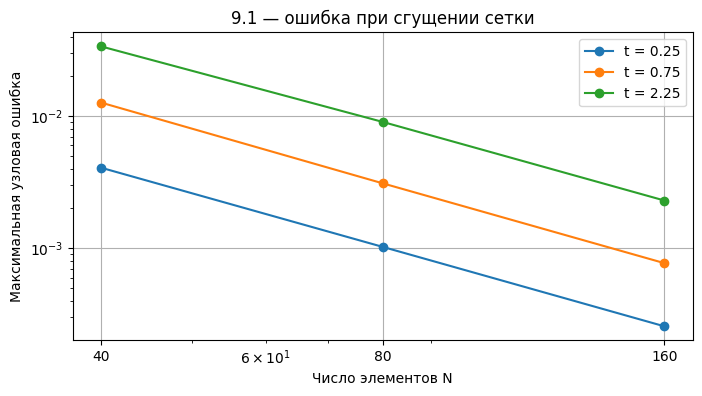

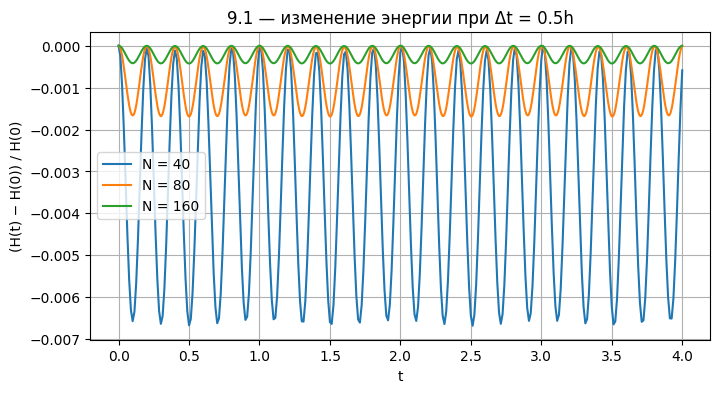

In [5]:
fig, ax = plt.subplots()
for t in OBS_TIMES:
    key = f'ε∞(t={t})'
    ax.loglog(err_table.index, err_table[key], 'o-', label=f't = {t}')
ax.set(xticks=list(MESHES), xlabel='Число элементов N', ylabel='Максимальная узловая ошибка', title='9.1 — ошибка при сгущении сетки')
ax.set_xticklabels([str(n) for n in MESHES])
ax.legend()
plt.show()

fig, ax = plt.subplots()
for N in MESHES:
    x, times, U, V, H = green[N]
    ax.plot(times, rel_energy(H), label=f'N = {N}')
ax.set(xlabel='t', ylabel='(H(t) − H(0)) / H(0)', title='9.1 — изменение энергии при Δt = 0.5h')
ax.legend()
plt.show()

## 6. Анимация колебаний с точным решением

Сетка $N=80$. Синяя линия — метод Верле с диагональной массой, пунктир — точное решение.

In [6]:
N = 80
x, times, U, V, H = green[N]
frames = np.unique(np.linspace(0, len(times) - 1, 100, dtype=int))
fig, ax = plt.subplots(figsize=(7.6, 3.6))
line_fe, = ax.plot(x, np.r_[0, U[0], 0], lw=2, label='МКЭ, диагональная масса')
line_exact, = ax.plot(x, exact(x, 0), '--', lw=1.7, label='Точное решение')
heading = ax.set_title('t = 0.000')
ax.set(xlim=(0, 1), ylim=(-1.45, 1.45), xlabel='x', ylabel='u(x,t)')
ax.legend(loc='upper right')

def animate_green(k):
    i = frames[k]
    line_fe.set_ydata(np.r_[0, U[i], 0])
    line_exact.set_ydata(exact(x, times[i]))
    heading.set_text(f'9.1 — t = {times[i]:.3f}')
    return line_fe, line_exact, heading

ani_green = FuncAnimation(fig, animate_green, frames=len(frames), interval=65, blit=False)
plt.close(fig)
display(HTML(ani_green.to_jshtml(fps=15, default_mode='loop')))

# Задание 9.2. Согласованная и диагональная массы

## 7. Собственные частоты и предельные шаги

Для каждой массы решается обобщённая задача
$$Kz_j=\omega_{h,j}^{2}M_*z_j,\qquad \Delta t_{\mathrm{crit}}=\frac{2}{\omega_{h,\max}}.$$

Частоты точного стержня: $\omega_j=j\pi$. **Рабочий шаг строго меньше** $\Delta t_{\mathrm{crit}}$. Относительная ошибка частоты: $(\omega_{h,j}-j\pi)/(j\pi)$.

In [7]:
spectra = {}
frequency_rows = []
limit_rows = []

for N in MESHES:
    x, K, M, ML = assemble(N)
    for name, mass in [('Диагональная', ML), ('Согласованная', M)]:
        eigval, eigvec = eigh(K, mass, check_finite=False)
        omega = np.sqrt(eigval)
        spectra[N, name] = (omega, eigvec)
        for j in range(1, 6):
            frequency_rows.append({
                'N': N, 'Масса': name, 'j': j, 'ω_h': omega[j-1],
                'ω точн.': j * np.pi,
                'Ошибка, %': 100*(omega[j-1]/(j*np.pi)-1)
            })
        limit_rows.append({'N': N, 'Масса': name, 'ω_max': omega[-1], 'Δt_crit': 2/omega[-1]})

freq_table = pd.DataFrame(frequency_rows)
crit_table = pd.DataFrame(limit_rows)
display(freq_table.round({'ω_h': 6, 'ω точн.': 6, 'Ошибка, %': 5}))
print('Предельные шаги:')
display(crit_table.round(8))

# Для равномерной сетки спектр известен аналитически; сверяем результаты eigh.
for N_check in MESHES:
    theta = np.pi*np.arange(1, N_check)/N_check
    omega_L = 2*N_check*np.sin(theta/2)
    omega_M = N_check*np.sqrt(6*(1-np.cos(theta))/(2+np.cos(theta)))
    assert np.allclose(spectra[N_check, 'Диагональная'][0], omega_L, rtol=1e-10)
    assert np.allclose(spectra[N_check, 'Согласованная'][0], omega_M, rtol=1e-10)
print('Спектры МКЭ сверены с аналитическими формулами для равномерной сетки.')

,N,Масса,j,ω_h,ω точн.,"Ошибка, %"
0,40,Диагональная,1,3.140785,3.141593,-0.02570
1,40,Диагональная,2,6.276728,6.283185,-0.10278
2,40,Диагональная,3,9.402992,9.424778,-0.23116
3,40,Диагональная,4,12.514757,12.566371,-0.41073
4,40,Диагональная,5,15.607226,15.707963,-0.64131
5,40,Согласованная,1,3.142400,3.141593,0.02570
6,40,Согласованная,2,6.289647,6.283185,0.10284
7,40,Согласованная,3,9.446594,9.424778,0.23148
8,40,Согласованная,4,12.618110,12.566371,0.41173
9,40,Согласованная,5,15.809080,15.707963,0.64373


Предельные шаги:


,N,Масса,ω_max,Δt_crit
0,40,Диагональная,79.938323,0.025019
1,40,Согласованная,138.244320,0.014467
2,80,Диагональная,159.969158,0.012502
3,80,Согласованная,276.967965,0.007221
4,160,Диагональная,319.984579,0.006250
5,160,Согласованная,554.176139,0.003609


Спектры МКЭ сверены с аналитическими формулами для равномерной сетки.


## 8. Сравнение спектров

Для наглядности показаны ошибки первых 15 частот на сетке $N=80$. Положительная ошибка означает завышение частоты, отрицательная — занижение.

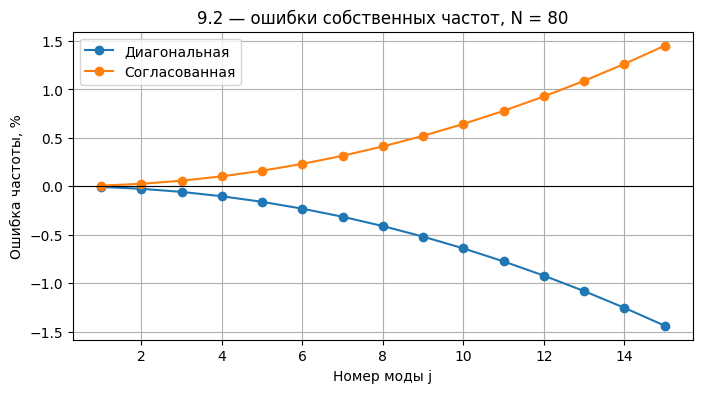

In [ ]:
N = 80
fig, ax = plt.subplots()
j = np.arange(1, 16)
for name in ('Диагональная', 'Согласованная'):
    omega = spectra[N, name][0][:15]
    ax.plot(j, 100*(omega/(j*np.pi)-1), 'o-', label=name)
ax.axhline(0, c='black', lw=0.8)
ax.set(xlabel='Номер моды j', ylabel='Ошибка частоты, %', title='9.2 — ошибки собственных частот, N = 80')
ax.legend()
plt.show()

## 9. Одинаковый шаг и шаг вдвое меньше

Фиксируем сетку $N=80$ и $T=12$. Выбираем $\Delta t=h/2$, затем $\Delta t=h/4$. Оба шага проверяются по вычисленным пределам для **двух** масс. Сравниваются сигнал в середине стержня, максимальная узловая ошибка и относительное изменение энергии.

In [8]:
N = 80
T_YELLOW = 12.0
x, K, M, ML = assemble(N)
dt_common = 0.5/N
crit_here = crit_table[crit_table['N']==N]
assert dt_common < crit_here['Δt_crit'].min()

runs = {}
comparison_rows = []
for name, mass, lump in [('Диагональная', ML, True), ('Согласованная', M, False)]:
    for divisor, step_label in [(1, 'h/2'), (2, 'h/4')]:
        dt = dt_common/divisor
        times, U, V, H = verlet(K, mass, exact(x[1:-1], 0), dt, T_YELLOW, lump)
        runs[name, step_label] = (times, U, V, H)
        errors = []
        for t in (*OBS_TIMES, 12.0):
            ind = row_at(times, t)
            errors.append(np.max(np.abs(U[ind]-exact(x[1:-1], t))))
        comparison_rows.append({
            'Масса': name, 'Шаг': step_label, 'Δt': dt,
            'ε∞(0.25)': errors[0], 'ε∞(0.75)': errors[1],
            'ε∞(2.25)': errors[2], 'ε∞(12)': errors[3],
            'max |ΔH/H₀|': np.max(np.abs(rel_energy(H)))
        })

compare_table = pd.DataFrame(comparison_rows)
display(compare_table.style.format({k:'{:.6g}' for k in compare_table.select_dtypes('number').columns}))

,Масса,Шаг,Δt,ε∞(0.25),ε∞(0.75),ε∞(2.25),ε∞(12),max |ΔH/H₀|
0,Диагональная,h/2,0.00625,0.00102351,0.00309897,0.00903775,0.00771363,0.00169089
1,Диагональная,h/4,0.003125,0.00127763,0.00387721,0.0112264,0.012004,0.000422716
2,Согласованная,h/2,0.00625,0.00171803,0.00507428,0.0159259,0.0213037,0.00170153
3,Согласованная,h/4,0.003125,0.00145832,0.00431742,0.0134607,0.0154183,0.00042541


## 10. Сигнал $u(0.5,t)$ и энергия

Сначала сравнение масс при одном устойчивом шаге $h/2$. Затем изменение энергии для двух масс при шагах $h/2$ и $h/4$.

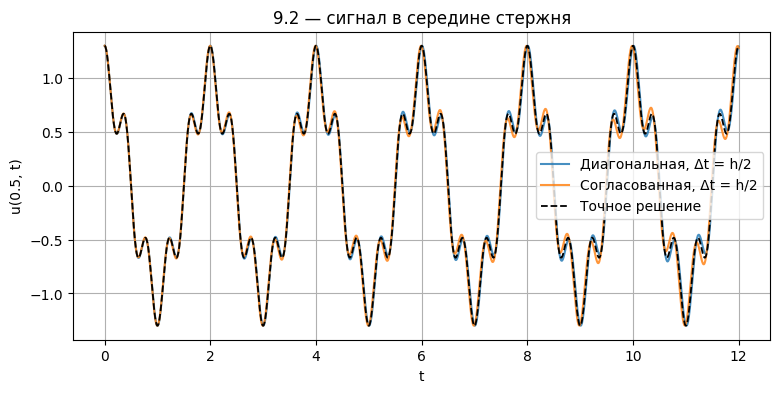

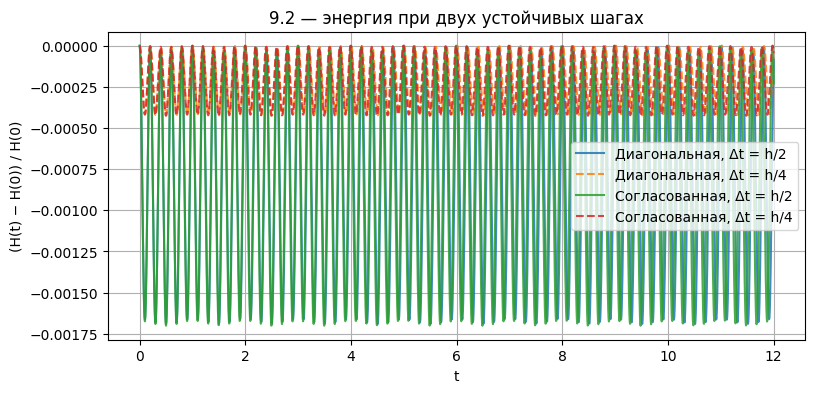

In [9]:
mid_index = N//2 - 1  # x = 0.5 среди свободных узлов
fig, ax = plt.subplots(figsize=(9, 4))
for name in ('Диагональная', 'Согласованная'):
    times, U, V, H = runs[name, 'h/2']
    ax.plot(times, U[:, mid_index], label=f'{name}, Δt = h/2', alpha=0.82)
ax.plot(times, exact(0.5, times), '--', lw=1.3, c='black', label='Точное решение')
ax.set(xlabel='t', ylabel='u(0.5, t)', title='9.2 — сигнал в середине стержня')
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for name in ('Диагональная', 'Согласованная'):
    for label, style in [('h/2', '-'), ('h/4', '--')]:
        times, U, V, H = runs[name, label]
        ax.plot(times, rel_energy(H), ls=style, label=f'{name}, Δt = {label}', alpha=0.85)
ax.set(xlabel='t', ylabel='(H(t) − H(0)) / H(0)', title='9.2 — энергия при двух устойчивых шагах')
ax.legend()
plt.show()

## 11. Накопление фазовой ошибки

Для отдельной моды метод Верле задаёт численную частоту
$$\widetilde\omega_j=\frac{2}{\Delta t}\arcsin\left(\frac{\Delta t\,\omega_{h,j}}2\right).$$

Поэтому ошибка фазы относительно непрерывного стержня к моменту $T$ равна
$$\Delta\varphi_j(T)=(\widetilde\omega_j-j\pi)T.$$

Ниже приведены результаты для мод $j=1$ и $j=5$ и обеих величин шага. Эта формула разделяет пространственную погрешность частоты и дополнительный сдвиг из-за шага по времени.

,Масса,Шаг,Мода,ω_h,ω_Верле,"Δφ(12), рад"
0,Диагональная,h/2,1,3.141391,3.141441,-0.001817
1,Диагональная,h/2,5,15.682742,15.689027,-0.227233
2,Диагональная,h/4,1,3.141391,3.141403,-0.002271
3,Диагональная,h/4,5,15.682742,15.684312,-0.283811
4,Согласованная,h/2,1,3.141795,3.141845,0.003028
5,Согласованная,h/2,5,15.733208,15.739554,0.379087
6,Согласованная,h/4,1,3.141795,3.141807,0.002574
7,Согласованная,h/4,5,15.733208,15.734793,0.321961


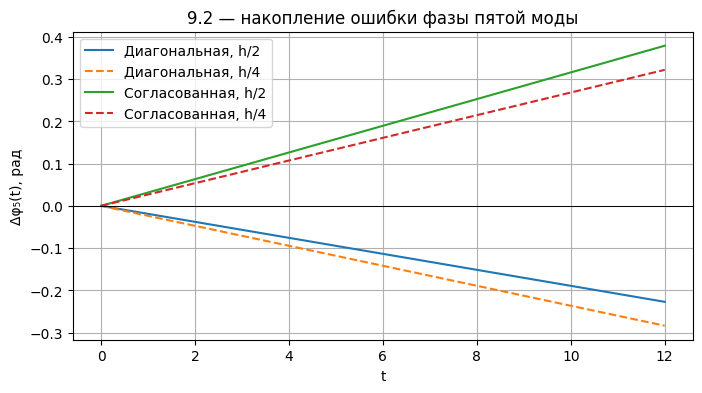

In [10]:
phase_rows = []
for name in ('Диагональная', 'Согласованная'):
    omega = spectra[N, name][0]
    for label, dt in [('h/2', dt_common), ('h/4', dt_common/2)]:
        for j in (1, 5):
            numerical_omega = 2/dt * np.arcsin(0.5*dt*omega[j-1])
            phase_rows.append({
                'Масса': name, 'Шаг': label, 'Мода': j,
                'ω_h': omega[j-1], 'ω_Верле': numerical_omega,
                'Δφ(12), рад': (numerical_omega-j*np.pi)*T_YELLOW
            })
phase_table = pd.DataFrame(phase_rows)
display(phase_table.round(6))

fig, ax = plt.subplots(figsize=(8, 4))
for name in ('Диагональная', 'Согласованная'):
    omega5 = spectra[N, name][0][4]
    for label, dt, style in [('h/2', dt_common, '-'), ('h/4', dt_common/2, '--')]:
        om_verlet = 2/dt*np.arcsin(dt*omega5/2)
        t_grid = np.linspace(0, T_YELLOW, 200)
        ax.plot(t_grid, (om_verlet-5*np.pi)*t_grid, style, label=f'{name}, {label}')
ax.axhline(0, c='black', lw=0.7)
ax.set(xlabel='t', ylabel='Δφ₅(t), рад', title='9.2 — накопление ошибки фазы пятой моды')
ax.legend()
plt.show()

## 12. Устойчивость возле предельного шага

Для каждой массы отдельно проверяются $0.9\Delta t_{\mathrm{crit}}$ и $1.05\Delta t_{\mathrm{crit}}$. В начальное перемещение добавляется возмущение $10^{-8}z_{\max}$, где $z_{\max}$ — последняя собственная форма, нормированная условием $\max_i|z_{\max,i}|=1$.

Измеряется амплитуда этой формы через $M_*$-ортогональную проекцию. Показана **наибольшая достигнутая амплитуда**, делённая на $10^{-8}$: так осцилляции не скрывают рост. Расчёт прерывается при $\max|U_i|>10^{25}$ или появлении нечисловых значений — до переполнения.

,Масса,Δt/Δt_crit,Δt,t последн.,max |a_max|/10⁻⁸,Остановка по порогу
0,Диагональная,0.900000,0.01125217,3.995,1.0000e+00,False
1,Диагональная,1.050000,0.01312753,1.588,6.2709e+32,True
2,Согласованная,0.900000,0.006498947,3.997,1.0000e+00,False
3,Согласованная,1.050000,0.007582104,0.9174,6.2709e+32,True


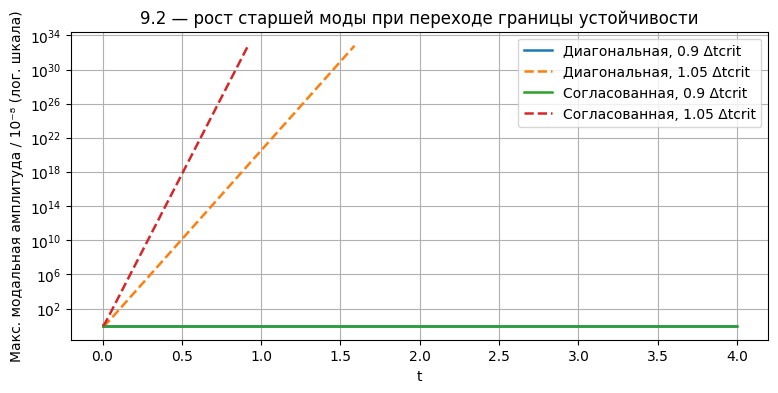

In [11]:
def stability_test(K, mass, u0, zmax, dt, T, lumped, cutoff=1e25):
    accel = make_acceleration(K, mass, lumped)
    denom = zmax @ (mass @ zmax)
    u = u0 + 1e-8*zmax
    v = np.zeros_like(u)
    a = accel(u)
    time_hist, mode_hist = [0.0], [float(zmax @ (mass @ u) / denom)]
    stopped = False
    for k in range(int(np.floor(T/dt))):
        vh = v + 0.5*dt*a
        u_new = u + dt*vh
        if (not np.all(np.isfinite(u_new))) or np.max(np.abs(u_new)) > cutoff:
            stopped = True
            break
        anew = accel(u_new)
        v = vh + 0.5*dt*anew
        u = u_new
        a = anew
        time_hist.append((k+1)*dt)
        mode_hist.append(float(zmax @ (mass @ u) / denom))
    return np.array(time_hist), np.array(mode_hist), stopped

T_STAB = 4.0
stability_runs = {}
stab_rows = []
for name, mass, lump in [('Диагональная', ML, True), ('Согласованная', M, False)]:
    omega, eigenvectors = spectra[N, name]
    zmax = eigenvectors[:, -1].copy()
    zmax /= np.max(np.abs(zmax))
    assert np.isclose(np.max(np.abs(zmax)), 1.0)
    crit = 2 / omega[-1]
    for factor in (0.9, 1.05):
        dt = factor*crit
        tt, amp, stopped = stability_test(K, mass, exact(x[1:-1], 0), zmax, dt, T_STAB, lump)
        envelope = np.maximum.accumulate(np.abs(amp))/1e-8
        stability_runs[name, factor] = (tt, envelope)
        stab_rows.append({
            'Масса': name, 'Δt/Δt_crit': factor, 'Δt': dt,
            't последн.': tt[-1], 'max |a_max|/10⁻⁸': envelope.max(),
            'Остановка по порогу': stopped
        })

stab_table = pd.DataFrame(stab_rows)
display(stab_table.style.format({'Δt':'{:.7g}', 't последн.':'{:.4g}', 'max |a_max|/10⁻⁸':'{:.4e}'}))

fig, ax = plt.subplots(figsize=(9, 4))
for name in ('Диагональная', 'Согласованная'):
    for factor, linestyle in [(0.9, '-'), (1.05, '--')]:
        tt, envelope = stability_runs[name, factor]
        ax.semilogy(tt, envelope, linestyle, lw=1.8, label=f'{name}, {factor:g} Δtcrit')
ax.set(xlabel='t', ylabel='Макс. модальная амплитуда / 10⁻⁸ (лог. шкала)',
       title='9.2 — рост старшей моды при переходе границы устойчивости')
ax.legend()
plt.show()

## 13. Анимация: сравнение двух масс и точного решения

Обе схемы работают на сетке $N=80$ с **одинаковым устойчивым** шагом $\Delta t=h/2$. На кадрах показаны одинаковые физические моменты времени.

In [12]:
t_l, U_l, _, _ = runs['Диагональная', 'h/2']
t_c, U_c, _, _ = runs['Согласованная', 'h/2']
assert np.allclose(t_l, t_c)
anim_ids = np.unique(np.linspace(0, row_at(t_l, 4.0), 95, dtype=int))
fig, ax = plt.subplots(figsize=(7.6, 3.6))
line_l, = ax.plot(x, np.r_[0, U_l[0], 0], lw=1.8, label='Диагональная масса')
line_c, = ax.plot(x, np.r_[0, U_c[0], 0], lw=1.8, label='Согласованная масса')
line_ref, = ax.plot(x, exact(x, 0), 'k--', lw=1.2, label='Точное решение')
title = ax.set_title('t = 0')
ax.set(xlim=(0, 1), ylim=(-1.45, 1.45), xlabel='x', ylabel='u(x,t)')
ax.legend(loc='upper right')

def animate_both(k):
    i = anim_ids[k]
    line_l.set_ydata(np.r_[0, U_l[i], 0])
    line_c.set_ydata(np.r_[0, U_c[i], 0])
    line_ref.set_ydata(exact(x, t_l[i]))
    title.set_text(f'9.2 — t = {t_l[i]:.3f}')
    return line_l, line_c, line_ref, title

ani_both = FuncAnimation(fig, animate_both, frames=len(anim_ids), interval=70, blit=False)
plt.close(fig)
display(HTML(ani_both.to_jshtml(fps=15, default_mode='loop')))

## 14. Выводы

1. Сгущение сетки уменьшает максимальную узловую ошибку в заданные моменты. Её численные значения приведены в таблице раздела 4.
2. **Диагональная масса** занижает собственные частоты и даёт больший предельный шаг; **согласованная масса** завышает частоты и требует меньшего шага. Это видно из таблиц раздела 7.
3. При $\Delta t<\Delta t_{\mathrm{crit}}$ энергия в методе Верле **колеблется около начальной**, но не обязана оставаться в точности постоянной. Уменьшение $\Delta t$ снижает амплитуду этих отклонений.
4. При $0.9\Delta t_{\mathrm{crit}}$ возмущённая старшая мода остаётся ограниченной; при $1.05\Delta t_{\mathrm{crit}}$ её амплитуда быстро растёт. Значение $\Delta t=\Delta t_{\mathrm{crit}}$ не используется как рабочее.
5. Ошибка фазы зависит и от пространственной аппроксимации (частоты $\omega_{h,j}$), и от шага Верле (частоты $\widetilde\omega_j$). Поэтому **хорошее сохранение энергии не гарантирует точной фазы**; для отдельных мод пространственная и временная погрешности могут частично компенсироваться.